<a href="https://colab.research.google.com/github/machindie/Analisis-Cluster-Jaringan-Internet-Gratis/blob/main/FuzzyCMeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Import Library**

In [ ]:
!pip install scikit-fuzzy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 9.7 MB/s eta 0:00:00


In [ ]:
# 1. Import Library
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import silhouette_score
import skfuzzy as fuzz
from scipy.stats import zscore
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# **Load Data**

In [ ]:
# 2. Load Data (Ganti dengan data asli Anda)
data = pd.read_excel("DATAKELJAR.xlsx")  # Pastikan file ini berisi kolom sesuai
data

,DESA,JUMLAH JARINGAN INTERNET,JUMLAH PENDUDUK,LUAS WILAYAH,KEPADATAN
0,LEKOBALO,1,3933,2.09,1881.818182
1,BULIIDE,1,3149,2.95,1067.457627
2,BULADU,3,4650,0.92,5054.347826
3,BIAWU,2,3638,0.28,12992.857143
4,LIMBA U I,2,3905,0.52,7509.615385
5,DULOMO SELATAN,3,5199,2.24,2320.982143
6,DEMBE JAYA,1,3484,0.96,3629.166667
7,HUANGOBOTU,3,8869,1.22,7269.672131
8,LIBUO,1,5679,1.33,4269.924812
9,HELEDULAA UTARA,1,5164,0.97,5323.711340


# **Statistika Deskriptif**

In [ ]:
# Statistik deskriptif ringkasan (count, mean, std, min, 25%, 50%, 75%, max)
print(data.describe())

       JUMLAH JARINGAN INTERNET  JUMLAH PENDUDUK  LUAS WILAYAH     KEPADATAN  \
count                 50.000000        50.000000      50.00000     50.000000   
mean                   2.300000      4087.200000       1.30020   4596.563890   
std                    1.908627      1374.756349       0.97107   2991.416510   
min                    1.000000      1402.000000       0.28000    519.039451   
25%                    1.000000      3150.250000       0.67250   2366.148695   
50%                    1.500000      3773.000000       0.96500   4118.962406   
75%                    3.000000      5104.000000       1.51500   6240.880503   
max                   10.000000      8869.000000       5.83000  14272.222222   

         cluster  rasio_per_1000  rasio_per_km2  rasio_per_kepadatan  \
count  50.000000       50.000000      50.000000            50.000000   
mean    0.600000        0.584607       2.814858             0.000648   
std     0.494872        0.482130       3.167437             0.0

# **Preprocessing Data**

In [ ]:
#1 MISSING VALUE

# Cek total missing value per kolom
print("Jumlah missing value per kolom:")
print(data.isnull().sum())

# (Opsional) Cek proporsi missing value
print("\nProporsi missing value per kolom:")
print(data.isnull().mean())

Jumlah missing value per kolom:
DESA                        0
JUMLAH JARINGAN INTERNET    0
JUMLAH PENDUDUK             0
LUAS WILAYAH                0
KEPADATAN                   0
dtype: int64

Proporsi missing value per kolom:
DESA                        0.0
JUMLAH JARINGAN INTERNET    0.0
JUMLAH PENDUDUK             0.0
LUAS WILAYAH                0.0
KEPADATAN                   0.0
dtype: float64


Kolom-kolom yang memiliki outlier dan barisnya:

Kolom: JUMLAH JARINGAN INTERNET
Indeks outlier: [28, 37]

Kolom: JUMLAH PENDUDUK
Indeks outlier: [7]

Kolom: LUAS WILAYAH
Indeks outlier: [1, 18, 43, 48]

Kolom: KEPADATAN
Indeks outlier: [3, 46]


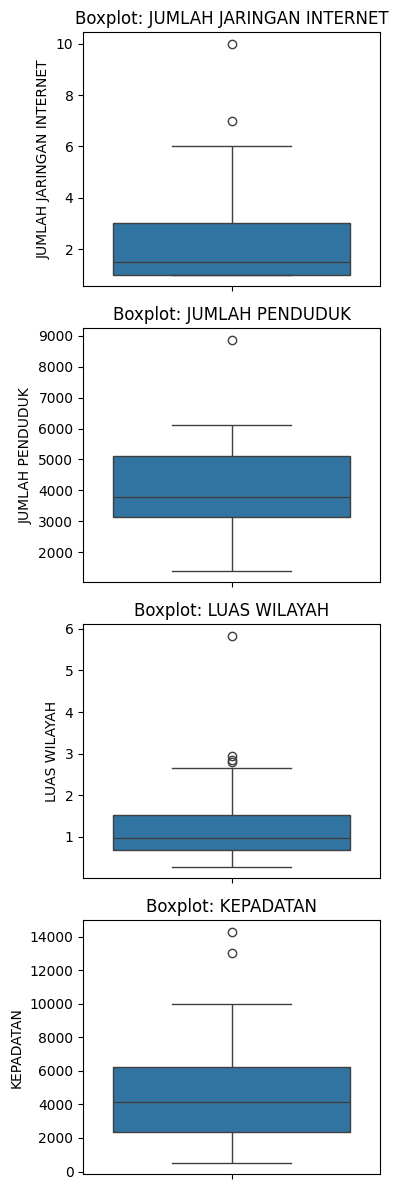

In [ ]:
#2 OUTLIER

# Kolom numerik yang ingin dicek
kolom_numerik = ['JUMLAH JARINGAN INTERNET', 'JUMLAH PENDUDUK', 'LUAS WILAYAH', 'KEPADATAN']

# Fungsi untuk mendeteksi outlier dan mengembalikan indeks baris yang merupakan outlier
def cari_outlier(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return series[(series < lower_bound) | (series > upper_bound)].index

# Dictionary untuk menyimpan hasil outlier per kolom
outlier_dict = {}

for kolom in kolom_numerik:
    indeks_outlier = cari_outlier(data[kolom])
    if not indeks_outlier.empty:
        outlier_dict[kolom] = indeks_outlier.tolist()

# Tampilkan hasil outlier
if outlier_dict:
    print("Kolom-kolom yang memiliki outlier dan barisnya:")
    for kolom, indeks in outlier_dict.items():
        print(f"\nKolom: {kolom}")
        print(f"Indeks outlier: {indeks}")

    # Tampilkan boxplot hanya untuk kolom yang punya outlier
    plt.figure(figsize=(4, 3 * len(outlier_dict)))
    for i, kolom in enumerate(outlier_dict):
        plt.subplot(len(outlier_dict), 1, i+1)
        sns.boxplot(y=data[kolom])
        plt.title(f'Boxplot: {kolom}')
        plt.tight_layout()
    plt.show()
else:
    print("Tidak ada outlier yang terdeteksi di kolom-kolom numerik.")

In [ ]:
#4 Uji Multikolinearitas (VIF)

fitur_awal = ['JUMLAH JARINGAN INTERNET', 'JUMLAH PENDUDUK', 'LUAS WILAYAH', 'KEPADATAN']
X_vif = add_constant(data[fitur_awal])
vif_df = pd.DataFrame()
vif_df["variabel"] = X_vif.columns
vif_df["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
print(vif_df)

                   variabel        VIF
0                     const  17.446433
1  JUMLAH JARINGAN INTERNET   1.173273
2           JUMLAH PENDUDUK   1.420464
3              LUAS WILAYAH   1.964379
4                 KEPADATAN   2.268983


In [ ]:
#5 standarisasi data menggunakan RobustScaler

# Kolom numerik yang ingin diskalakan
kolom_numerik = ['JUMLAH JARINGAN INTERNET', 'JUMLAH PENDUDUK', 'LUAS WILAYAH', 'KEPADATAN']

# Inisialisasi scaler
scaler = RobustScaler()

# Transformasi kolom numerik
scaled_data = scaler.fit_transform(data[kolom_numerik])
scaled_data

array([[-2.50000000e-01,  8.18937940e-02,  1.33531157e+00,
        -5.77367502e-01],
       [-2.50000000e-01, -3.19385797e-01,  2.35608309e+00,
        -7.87539610e-01],
       [ 7.50000000e-01,  4.48880358e-01, -5.34124629e-02,
         2.41406494e-01],
       [ 2.50000000e-01, -6.90978887e-02, -8.13056380e-01,
         2.29019586e+00],
       [ 2.50000000e-01,  6.75623800e-02, -5.28189911e-01,
         8.75067784e-01],
       [ 7.50000000e-01,  7.29878439e-01,  1.51335312e+00,
        -4.64027022e-01],
       [-2.50000000e-01, -1.47920665e-01, -5.93471810e-03,
        -1.26407649e-01],
       [ 7.50000000e-01,  2.60831734e+00,  3.02670623e-01,
         8.13142659e-01],
       [-2.50000000e-01,  9.75559821e-01,  4.33234421e-01,
         3.89607368e-02],
       [-2.50000000e-01,  7.11964171e-01,  5.93471810e-03,
         3.10924470e-01],
       [ 7.50000000e-01, -4.95457454e-01, -6.11275964e-01,
         5.45681877e-01],
       [ 7.50000000e-01,  3.30134357e-01,  6.70623145e-01,
      

# **Fuzzy C-Means**


Tabel Nilai Partition Coefficient (PC):
m      2.0     2.5     3.0     4.0
c                                 
2   0.6650  0.5840  0.5446  0.5151
3   0.5858  0.4686  0.4081  0.3599
4   0.5096  0.3905  0.3320  0.2723
5   0.4697  0.3477  0.2790  0.2308
6   0.4374  0.3080  0.2400  0.1985
7   0.4433  0.3052  0.2157  0.1829
8   0.4337  0.2932  0.2396  0.1691
9   0.4092  0.3092  0.2472  0.1623
10  0.4232  0.2978  0.2555  0.1552


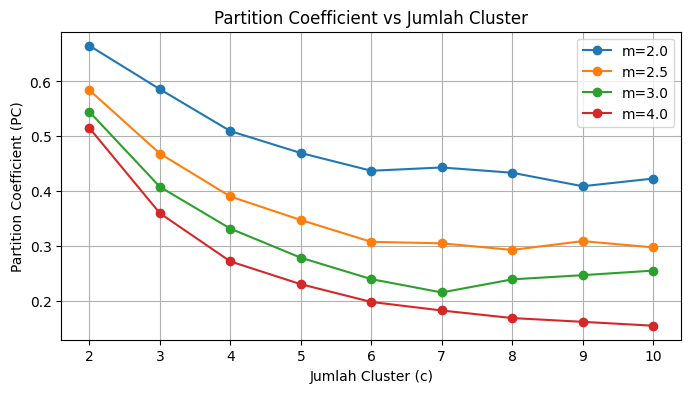

In [ ]:
# Parameter
m_values = [2.0, 2.5, 3.0, 4.0]
cluster_range = range(2, 11)  # C dari 2 sampai 10

# Simpan hasil PC dalam list of dict
results = []

# Loop m dan c
for m in m_values:
    for c in cluster_range:
        cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(
            scaled_data.T, c, m=m, error=0.005, maxiter=1000, init=None
        )
        pc = np.sum(u ** 2) / u.shape[1]  # Partition Coefficient
        results.append({"m": m, "c": c, "PC": pc})

# Buat dataframe hasil
df_pc = pd.DataFrame(results)

# Tampilkan sebagai tabel
print("\nTabel Nilai Partition Coefficient (PC):")
print(df_pc.pivot(index='c', columns='m', values='PC').round(4))

# Visualisasi PC
plt.figure(figsize=(8, 4))
for m in m_values:
    subset = df_pc[df_pc['m'] == m]
    plt.plot(subset['c'], subset['PC'], marker='o', label=f'm={m}')
plt.title("Partition Coefficient vs Jumlah Cluster")
plt.xlabel("Jumlah Cluster (c)")
plt.ylabel("Partition Coefficient (PC)")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import numpy as np

# Cek bentuk data
n, m = scaled_data.shape
print(f"Jumlah data: {n}, Jumlah atribut: {m}")

Jumlah data: 50, Jumlah atribut: 4


In [ ]:
c = 2               # jumlah cluster (bisa kamu sesuaikan, misalnya dari hasil k-means)
m_fuzzy = 2         # tingkat fuzziness (harus > 1)
max_iter = 100      # jumlah maksimum iterasi
error = 1e-5        # toleransi error konvergensi
obj_func_prev = 0   # inisialisasi fungsi objektif awal

In [ ]:
U = np.random.rand(n, c)
U = U / np.sum(U, axis=1, keepdims=True)

print("Matriks keanggotaan awal U:")
print(U)

Matriks keanggotaan awal U:
[[0.68649639 0.31350361]
 [0.82536194 0.17463806]
 [0.31125165 0.68874835]
 [0.87024129 0.12975871]
 [0.91251183 0.08748817]
 [0.17529001 0.82470999]
 [0.32819409 0.67180591]
 [0.54790727 0.45209273]
 [0.56959927 0.43040073]
 [0.27329687 0.72670313]
 [0.51008319 0.48991681]
 [0.83238336 0.16761664]
 [0.75079091 0.24920909]
 [0.7942678  0.2057322 ]
 [0.96803929 0.03196071]
 [0.85601098 0.14398902]
 [0.54850211 0.45149789]
 [0.22542493 0.77457507]
 [0.63691802 0.36308198]
 [0.68042989 0.31957011]
 [0.7011302  0.2988698 ]
 [0.30530885 0.69469115]
 [0.27619974 0.72380026]
 [0.86721256 0.13278744]
 [0.170494   0.829506  ]
 [0.98898615 0.01101385]
 [0.31425309 0.68574691]
 [0.85697962 0.14302038]
 [0.10704796 0.89295204]
 [0.56017056 0.43982944]
 [0.64203704 0.35796296]
 [0.67104613 0.32895387]
 [0.25084017 0.74915983]
 [0.2995414  0.7004586 ]
 [0.27492269 0.72507731]
 [0.79413538 0.20586462]
 [0.64827741 0.35172259]
 [0.67087734 0.32912266]
 [0.61448152 0.3855184

In [ ]:
def hitung_pusat_cluster(data, U, m):
    n, m_data = data.shape
    c = U.shape[1]
    V = np.zeros((c, m_data))
    Um = U ** m

    for k in range(c):
        numerator = np.sum(Um[:, k, None] * data, axis=0)
        denominator = np.sum(Um[:, k])
        V[k] = numerator / denominator
    return V

In [ ]:
def hitung_objektif(data, U, V, m):
    obj = 0.0
    Um = U ** m
    for i in range(data.shape[0]):
        for k in range(V.shape[0]):
            dist = np.linalg.norm(data[i] - V[k])
            obj += Um[i, k] * (dist ** 2)
    return obj

In [ ]:
def update_keanggotaan(data, V, m):
    n = data.shape[0]
    c = V.shape[0]
    U_new = np.zeros((n, c))

    for i in range(n):
        for k in range(c):
            dist_ik = np.linalg.norm(data[i] - V[k])
            if dist_ik == 0:
                U_new[i, :] = 0
                U_new[i, k] = 1
                break
            denom = 0
            for j in range(c):
                dist_ij = np.linalg.norm(data[i] - V[j])
                dist_ij = dist_ij if dist_ij != 0 else 1e-10
                denom += (dist_ik / dist_ij) ** (2 / (m - 1))
            U_new[i, k] = 1 / denom
    return U_new

In [ ]:
for t in range(max_iter):
    V = hitung_pusat_cluster(scaled_data, U, m_fuzzy)
    Pt = hitung_objektif(scaled_data, U, V, m_fuzzy)

    if abs(Pt - obj_func_prev) < error:
        print(f"Konvergen pada iterasi ke-{t}")
        break

    U = update_keanggotaan(scaled_data, V, m_fuzzy)
    obj_func_prev = Pt

Konvergen pada iterasi ke-16


In [ ]:
def partition_coefficient(U):
    return np.sum(U**2) / U.shape[0]

pc = partition_coefficient(U)
print(f"Partition Coefficient (PC): {pc}")

Partition Coefficient (PC): 0.6651803718977889


In [ ]:
label_fcm = np.argmax(U, axis=1)
print("Label cluster hasil Fuzzy C-Means:")
print(label_fcm)

Label cluster hasil Fuzzy C-Means:
[1 1 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 1 1 1 0 1 1 1 1 0 0 0 0 0 1 0 1 0 0 0 0
 0 0 0 0 1 0 1 1 1 0 1 1 1]


In [ ]:
print("Centroids (Pusat Cluster):")
print(V)

Centroids (Pusat Cluster):
[[ 0.55444931  0.30529482 -0.17016419  0.54535043]
 [ 0.09050239 -0.04042692  1.1696073  -0.43293209]]


In [ ]:
import numpy as np
from skfuzzy import cmeans
from sklearn.preprocessing import RobustScaler

# Misal data awal Anda sudah tersedia dalam variabel 'data' (numpy array)
# Contoh:
# data = np.array([[1, 2], [3, 4], [5, 6], [7, 8]])

data_trans = scaled_data.T  # Transpose agar bentuknya (fitur, sampel)

# Parameter Fuzzy C-Means
c = 2               # Jumlah cluster
m_fuzzy = 2         # Tingkat fuzziness (m > 1)
max_iter = 100      # Iterasi maksimum
error = 0.005       # Toleransi konvergensi

# Menjalankan algoritma Fuzzy C-Means
cntr, u, u0, d, jm, p, fpc = cmeans(
    data_trans,   # data input, shape = (fitur, sampel)
    c=c,                # jumlah cluster
    m=m_fuzzy,          # parameter fuzziness
    error=error,        # toleransi error
    maxiter=max_iter,   # iterasi maksimum
    init=None,          # inisialisasi centroid (None = random)
    seed=42             # seed random untuk reproduksibilitas
)

# cntr: pusat cluster, shape = (c, fitur)
# u: matriks keanggotaan, shape = (c, sampel)
# jm: nilai fungsi objektif tiap iterasi
# fpc: fuzzy partition coefficient (nilai kualitas clustering)

print("Pusat cluster (centroids):")
print(cntr)

print("\nMatriks keanggotaan (membership matrix):")
print(u)

print("\nNilai fuzzy partition coefficient (FPC):")
print(fpc)

# Menentukan cluster dengan derajat keanggotaan tertinggi
cluster_labels = np.argmax(u, axis=0)
print("\nLabel cluster untuk setiap data:")
print(cluster_labels)

Pusat cluster (centroids):
[[ 0.08992768 -0.04104792  1.16662439 -0.43234621]
 [ 0.55611455  0.30648325 -0.16998002  0.54630266]]

Matriks keanggotaan (membership matrix):
[[0.95913947 0.84143644 0.05908847 0.24519269 0.07734002 0.77955921
  0.45569894 0.36602668 0.47377383 0.2585795  0.15535549 0.64174076
  0.07649145 0.13727214 0.14634943 0.17631774 0.10882806 0.58877846
  0.84924704 0.81659764 0.4551143  0.89990957 0.74875141 0.88544775
  0.67112967 0.2844854  0.26579797 0.16328168 0.41233995 0.40355091
  0.75346699 0.42834479 0.95872997 0.21255232 0.27314848 0.20160877
  0.15911468 0.32590099 0.22442077 0.11480085 0.28989827 0.59303928
  0.21383996 0.64023935 0.71248767 0.78197512 0.28542138 0.50578807
  0.84767799 0.93302969]
 [0.04086053 0.15856356 0.94091153 0.75480731 0.92265998 0.22044079
  0.54430106 0.63397332 0.52622617 0.7414205  0.84464451 0.35825924
  0.92350855 0.86272786 0.85365057 0.82368226 0.89117194 0.41122154
  0.15075296 0.18340236 0.5448857  0.10009043 0.2512485

In [ ]:
import numpy as np
from skfuzzy import cmeans
from sklearn.preprocessing import RobustScaler

# Misal data awal Anda sudah tersedia dalam variabel 'data' (numpy array)
# Contoh:
# data = np.array([[1, 2], [3, 4], [5, 6], [7, 8]])

data_trans = scaled_data.T  # Transpose agar bentuknya (fitur, sampel)

# Parameter Fuzzy C-Means
c = 2               # Jumlah cluster
m_fuzzy = 2         # Tingkat fuzziness (m > 1)
max_iter = 1000      # Iterasi maksimum
error = 0.005       # Toleransi konvergensi

# Menjalankan algoritma Fuzzy C-Means
cntr, u, u0, d, jm, p, fpc = cmeans(
    data_trans,   # data input, shape = (fitur, sampel)
    c=c,                # jumlah cluster
    m=m_fuzzy,          # parameter fuzziness
    error=error,        # toleransi error
    maxiter=max_iter,   # iterasi maksimum
    init=None,          # inisialisasi centroid (None = random)
    seed=42             # seed random untuk reproduksibilitas
)

# cntr: pusat cluster, shape = (c, fitur)
# u: matriks keanggotaan, shape = (c, sampel)
# jm: nilai fungsi objektif tiap iterasi
# fpc: fuzzy partition coefficient (nilai kualitas clustering)

print("Pusat cluster (centroids):")
print(cntr)

print("\nMatriks keanggotaan (membership matrix):")
print(u)

print("\nNilai fuzzy partition coefficient (FPC):")
print(fpc)

# Menentukan cluster dengan derajat keanggotaan tertinggi
cluster_labels = np.argmax(u, axis=0)
print("\nLabel cluster untuk setiap data:")
print(cluster_labels)

Pusat cluster (centroids):
[[ 0.08992768 -0.04104792  1.16662439 -0.43234621]
 [ 0.55611455  0.30648325 -0.16998002  0.54630266]]

Matriks keanggotaan (membership matrix):
[[0.95913947 0.84143644 0.05908847 0.24519269 0.07734002 0.77955921
  0.45569894 0.36602668 0.47377383 0.2585795  0.15535549 0.64174076
  0.07649145 0.13727214 0.14634943 0.17631774 0.10882806 0.58877846
  0.84924704 0.81659764 0.4551143  0.89990957 0.74875141 0.88544775
  0.67112967 0.2844854  0.26579797 0.16328168 0.41233995 0.40355091
  0.75346699 0.42834479 0.95872997 0.21255232 0.27314848 0.20160877
  0.15911468 0.32590099 0.22442077 0.11480085 0.28989827 0.59303928
  0.21383996 0.64023935 0.71248767 0.78197512 0.28542138 0.50578807
  0.84767799 0.93302969]
 [0.04086053 0.15856356 0.94091153 0.75480731 0.92265998 0.22044079
  0.54430106 0.63397332 0.52622617 0.7414205  0.84464451 0.35825924
  0.92350855 0.86272786 0.85365057 0.82368226 0.89117194 0.41122154
  0.15075296 0.18340236 0.5448857  0.10009043 0.2512485

In [ ]:
cluster_labels

array([0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0,
       0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0,
       0, 0, 1, 0, 0, 0])

# **Visualisasi Hasil Clustering**

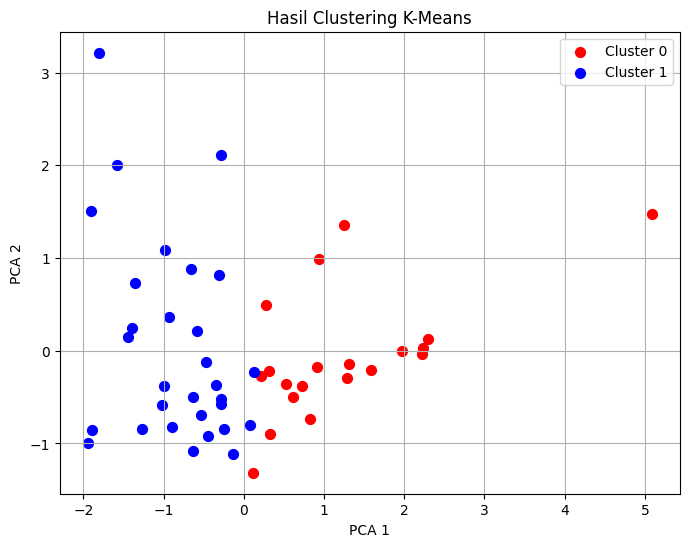

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8, 6))

colors = ['red', 'blue']  # Warna untuk cluster 0 dan 1

for cluster_id in np.unique(cluster_labels):
    idx = cluster_labels == cluster_id
    plt.scatter(data_2d[idx, 0], data_2d[idx, 1],
                c=colors[cluster_id], label=f'Cluster {cluster_id}', s=50)

plt.title("Hasil Clustering K-Means")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.legend()
plt.grid(True)
plt.show()


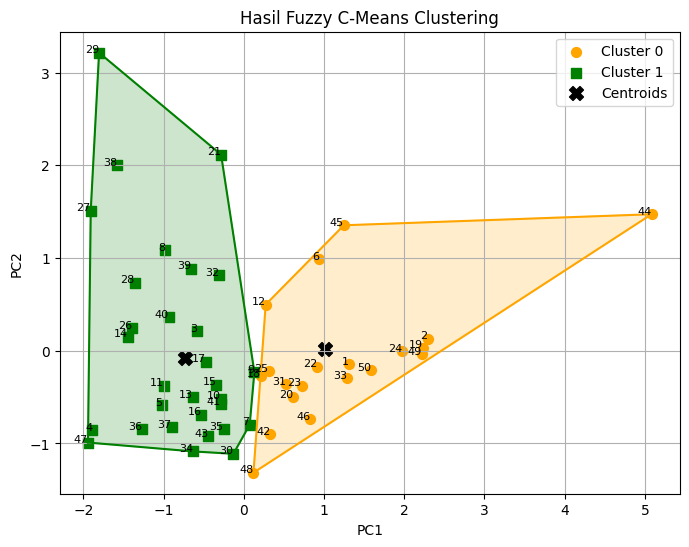

In [ ]:
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull
import numpy as np
from sklearn.decomposition import PCA

# Proyeksikan data dan centroid ke 2D menggunakan PCA
pca = PCA(n_components=2)
data_2d = pca.fit_transform(scaled_data)
centroids_2d = pca.transform(cntr)  # ubah pusat cluster ke ruang 2D

colors = ['orange', 'green', 'purple', 'cyan', 'brown']
markers = ['o', 's', '^', 'D', 'P']

plt.figure(figsize=(8, 6))

n_clusters = cntr.shape[0]

for i in range(n_clusters):
    points = data_2d[cluster_labels == i]
    indices = np.where(cluster_labels == i)[0]

    # Titik-titik cluster
    plt.scatter(points[:, 0], points[:, 1], color=colors[i], marker=markers[i],
                label=f'Cluster {i}', s=50)

    # Label angka
    for j, (x, y) in zip(indices, points):
        plt.text(x, y, str(j + 1), fontsize=8, ha='right')

    # Gambar convex hull jika titik cukup
    if len(points) >= 3:
        hull = ConvexHull(points)
        plt.fill(points[hull.vertices, 0], points[hull.vertices, 1], color=colors[i], alpha=0.2)
        for simplex in hull.simplices:
            plt.plot(points[simplex, 0], points[simplex, 1], c=colors[i])

# Plot centroid hasil FCM
plt.scatter(centroids_2d[:, 0], centroids_2d[:, 1], c='black', s=100, marker='X', label='Centroids')

plt.title("Hasil Fuzzy C-Means Clustering")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.grid(True)
plt.show()

# **Rata - Rata dan Interpretasi**

In [ ]:
# Tambahkan label cluster ke data asli
data['cluster'] = cluster_labels

# Hitung rata-rata tiap fitur per cluster
fitur = ['JUMLAH JARINGAN INTERNET', 'JUMLAH PENDUDUK', 'LUAS WILAYAH' , 'KEPADATAN']
rata2_cluster = data.groupby('cluster')[fitur].mean()

print("Rata-rata per cluster:")
print(rata2_cluster)

Rata-rata per cluster:
         JUMLAH JARINGAN INTERNET  JUMLAH PENDUDUK  LUAS WILAYAH    KEPADATAN
cluster                                                                      
0                        1.450000          3469.95      2.073500  1956.647635
1                        2.866667          4498.70      0.784667  6356.508060


In [ ]:
# Hitung median dari setiap fitur
median = data[fitur].median()

print("Median per fitur:")
print(median)

# Fungsi kategorisasi berdasarkan median
def kategorikan_median(nilai, median_val):
    if nilai < median_val:
        return 'Rendah'
    else:
        return 'Tinggi'

# DataFrame untuk menyimpan hasil kategorisasi
kategori_cluster_median = pd.DataFrame(index=rata2_cluster.index)

# Terapkan fungsi kategorisasi ke setiap fitur berdasarkan median
for kolom in fitur:
    kategori_cluster_median[kolom] = rata2_cluster[kolom].apply(lambda x: kategorikan_median(x, median[kolom]))

print("\nKategori (Tinggi/Rendah) per fitur di setiap cluster (berdasarkan median):")
print(kategori_cluster_median)


Median per fitur:
JUMLAH JARINGAN INTERNET       1.500000
JUMLAH PENDUDUK             3773.000000
LUAS WILAYAH                   0.965000
KEPADATAN                   4118.962406
dtype: float64

Kategori (Tinggi/Rendah) per fitur di setiap cluster (berdasarkan median):
        JUMLAH JARINGAN INTERNET JUMLAH PENDUDUK LUAS WILAYAH KEPADATAN
cluster                                                                
0                         Rendah          Rendah       Tinggi    Rendah
1                         Tinggi          Tinggi       Rendah    Tinggi


## 🧠 Kesimpulan:

1. Tidak masalah Anda menghitung rata-rata per cluster lalu mengkategorikan berdasarkan median global.

2. Ini sah secara statistik karena Anda membandingkan nilai ringkasan (summary statistics) dengan acuan global.

3. Jika data Anda terdistribusi tidak normal atau ada outlier, maka median sebagai batas lebih disarankan.

4. Jika distribusi data cukup normal dan Anda ingin pendekatan matematis yang lebih lazim, maka rata-rata sebagai batas juga valid.

In [ ]:
#JAGA JAGA
# Hitung rata-rata dari setiap fitur secara keseluruhan (bukan per cluster)
mean_global = data[fitur].mean()

print("Rata-rata per fitur (global):")
print(mean_global)

# Fungsi kategorisasi berdasarkan rata-rata
def kategorikan_mean(nilai, mean_val):
    if nilai < mean_val:
        return 'Rendah'
    else:
        return 'Tinggi'

# DataFrame untuk menyimpan hasil kategorisasi berdasarkan rata-rata
kategori_cluster_mean = pd.DataFrame(index=rata2_cluster.index)

# Terapkan fungsi kategorisasi ke setiap fitur berdasarkan rata-rata
for kolom in fitur:
    kategori_cluster_mean[kolom] = rata2_cluster[kolom].apply(lambda x: kategorikan_mean(x, mean_global[kolom]))

print("\nKategori (Tinggi/Rendah) per fitur di setiap cluster (berdasarkan rata-rata):")
print(kategori_cluster_mean)


Rata-rata per fitur (global):
JUMLAH JARINGAN INTERNET       2.30000
JUMLAH PENDUDUK             4087.20000
LUAS WILAYAH                   1.30020
KEPADATAN                   4596.56389
dtype: float64

Kategori (Tinggi/Rendah) per fitur di setiap cluster (berdasarkan rata-rata):
        JUMLAH JARINGAN INTERNET JUMLAH PENDUDUK LUAS WILAYAH KEPADATAN
cluster                                                                
0                         Rendah          Rendah       Tinggi    Rendah
1                         Tinggi          Tinggi       Rendah    Tinggi


# **Segmentasi Wilayah Hasil Cluster**

In [ ]:
data

,DESA,JUMLAH JARINGAN INTERNET,JUMLAH PENDUDUK,LUAS WILAYAH,KEPADATAN,cluster
0,LEKOBALO,1,3933,2.09,1881.818182,0
1,BULIIDE,1,3149,2.95,1067.457627,0
2,BULADU,3,4650,0.92,5054.347826,1
3,BIAWU,2,3638,0.28,12992.857143,1
4,LIMBA U I,2,3905,0.52,7509.615385,1
5,DULOMO SELATAN,3,5199,2.24,2320.982143,0
6,DEMBE JAYA,1,3484,0.96,3629.166667,1
7,HUANGOBOTU,3,8869,1.22,7269.672131,1
8,LIBUO,1,5679,1.33,4269.924812,1
9,HELEDULAA UTARA,1,5164,0.97,5323.711340,1


In [ ]:
import geopandas as gpd

# Load shapefile
shapefile = gpd.read_file("kota_gorontalo.shp")

# Pastikan ada kolom yang bisa dihubungkan antara shapefile dan data clustering
# Misalnya, 'ID_Kelurahan' adalah kolom yang bisa digunakan untuk menghubungkan data clustering
shapefile = shapefile.merge(data[['DESA', 'cluster']], how='left', on='DESA')

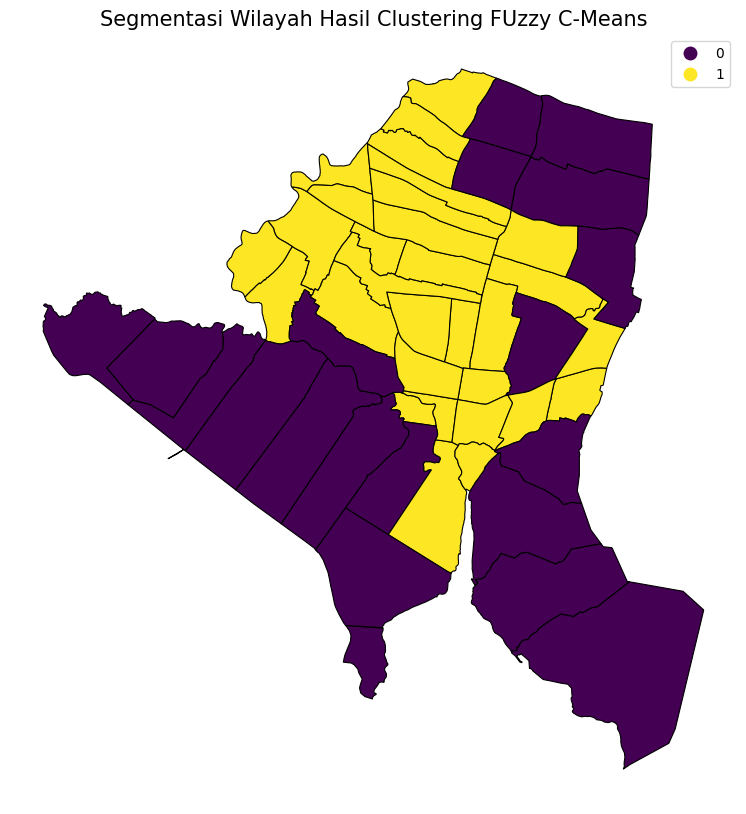

In [ ]:
#Segmentasi Wilayah Hasil Klaster
fig, ax = plt.subplots(figsize=(12, 10))
shapefile.plot(column='cluster', categorical=True, legend=True,
         cmap='viridis', linewidth=0.8, ax=ax, edgecolor='black')
plt.title('Segmentasi Wilayah Hasil Clustering FUzzy C-Means', fontsize=15)
plt.axis('off')
plt.show()

# **Evaluasi Kebijakan Pemerataan**

# quartil

In [ ]:
# 9. Hitung Rasio Pemerataan
data['rasio_per_1000'] = data['JUMLAH JARINGAN INTERNET'] / (data['JUMLAH PENDUDUK'] / 1000)
data['rasio_per_km2'] = data['JUMLAH JARINGAN INTERNET'] / data['LUAS WILAYAH']
data['rasio_per_kepadatan'] = data['JUMLAH JARINGAN INTERNET'] / data['KEPADATAN']

# 10. Hitung Skor Gabungan (tanpa z-score)
data['skor_total'] = (data['rasio_per_1000'] + data['rasio_per_km2'] + data['rasio_per_kepadatan']) / 3

# 11. Hitung Q1 dan Q3 dari skor_total
q1 = data['skor_total'].quantile(0.25)
q3 = data['skor_total'].quantile(0.75)

# 12. Klasifikasi Pemerataan berdasarkan Kuartil
def klasifikasi_q(skor):
    if skor < q1:
        return "Under-served"
    elif skor > q3:
        return "Over-served"
    else:
        return "Ideal"

data['kategori_pemerataan'] = data['skor_total'].apply(klasifikasi_q)

In [ ]:
q1

np.float64(0.38176229245074234)

In [ ]:
q3

np.float64(1.317581612058717)

In [ ]:
data['skor_total']

,skor_total
0,0.244420
1,0.219160
2,1.302208
3,2.564255
4,1.452861
5,0.639204
6,0.442990
7,0.932562
8,0.309400
9,0.408255


In [ ]:
data['kategori_pemerataan']

,kategori_pemerataan
0,Under-served
1,Under-served
2,Ideal
3,Over-served
4,Over-served
5,Ideal
6,Ideal
7,Ideal
8,Under-served
9,Ideal


# z score

In [ ]:
# 10. Hitung Z-Score dan Skor Gabungan
data['z1'] = zscore(data['rasio_per_1000'])
data['z2'] = zscore(data['rasio_per_km2'])
data['z3'] = zscore(data['rasio_per_kepadatan'])
data['skor_total_z'] = (data['z1'] + data['z2'] + data['z3']) / 3

# 11. Klasifikasi Pemerataan
def klasifikasi(z):
    if z < -0.5:
        return "Under-served"
    elif z > 0.5:
        return "Over-served"
    else:
        return "Ideal"

data['kategori_pemerataan_z'] = data['skor_total'].apply(klasifikasi)

In [ ]:
data['z1']

,z1
0,-0.692142
1,-0.559512
2,0.126872
3,-0.073027
4,-0.151782
5,-0.015867
6,-0.623488
7,-0.516151
8,-0.855926
9,-0.819133


In [ ]:
data['z2']

,z2
0,-0.745116
1,-0.789601
2,0.142241
3,1.380277
4,0.328899
5,-0.470586
6,-0.565503
7,-0.113484
8,-0.657921
9,-0.568927


In [ ]:
data['z3']

,z3
0,-0.240931
1,0.596876
2,-0.112497
3,-1.021010
4,-0.788736
5,1.332069
6,-0.769681
7,-0.486293
8,-0.855133
9,-0.950935


In [ ]:
data['skor_total_z']

,skor_total_z
0,-0.559397
1,-0.250746
2,0.052205
3,0.095413
4,-0.203873
5,0.281872
6,-0.652891
7,-0.371976
8,-0.789660
9,-0.779665


In [ ]:
data['kategori_pemerataan_z']

,kategori_pemerataan_z
0,Ideal
1,Ideal
2,Over-served
3,Over-served
4,Over-served
5,Over-served
6,Ideal
7,Over-served
8,Ideal
9,Ideal


# z score (benar)

In [ ]:
# 10. Hitung Z-Score dan Skor Gabungan
data['z1'] = zscore(data['rasio_per_1000'])
data['z2'] = zscore(data['rasio_per_km2'])
data['z3'] = zscore(data['rasio_per_kepadatan'])
data['skor_total'] = (data['z1'] + data['z2'] + data['z3']) / 3

# 11. Klasifikasi Pemerataan
def klasifikasi(z):
    if z < -0.5:
        return "Under-served"
    elif z > 0.5:
        return "Over-served"
    else:
        return "Ideal"

data['kategori_pemerataan'] = data['skor_total'].apply(klasifikasi)

In [ ]:
data['z1']

,z1
0,-0.692142
1,-0.559512
2,0.126872
3,-0.073027
4,-0.151782
5,-0.015867
6,-0.623488
7,-0.516151
8,-0.855926
9,-0.819133


In [ ]:
data['z2']

,z2
0,-0.745116
1,-0.789601
2,0.142241
3,1.380277
4,0.328899
5,-0.470586
6,-0.565503
7,-0.113484
8,-0.657921
9,-0.568927


In [ ]:
data['z3']

,z3
0,-0.240931
1,0.596876
2,-0.112497
3,-1.021010
4,-0.788736
5,1.332069
6,-0.769681
7,-0.486293
8,-0.855133
9,-0.950935


In [ ]:
data['skor_total']

,skor_total
0,-0.559397
1,-0.250746
2,0.052205
3,0.095413
4,-0.203873
5,0.281872
6,-0.652891
7,-0.371976
8,-0.789660
9,-0.779665


In [ ]:
data['kategori_pemerataan']

,kategori_pemerataan
0,Under-served
1,Ideal
2,Ideal
3,Ideal
4,Ideal
5,Ideal
6,Under-served
7,Ideal
8,Under-served
9,Under-served


# **JAGA JAGA**

Jumlah Cluster: 2, Silhouette Score: 0.2905
Jumlah Cluster: 3, Silhouette Score: 0.3096
Jumlah Cluster: 4, Silhouette Score: 0.2340
Jumlah Cluster: 5, Silhouette Score: 0.2309
Jumlah Cluster: 6, Silhouette Score: 0.2217
Jumlah Cluster: 7, Silhouette Score: 0.2460
Jumlah Cluster: 8, Silhouette Score: 0.2469
Jumlah Cluster: 9, Silhouette Score: 0.1779
Jumlah Cluster: 10, Silhouette Score: 0.1957


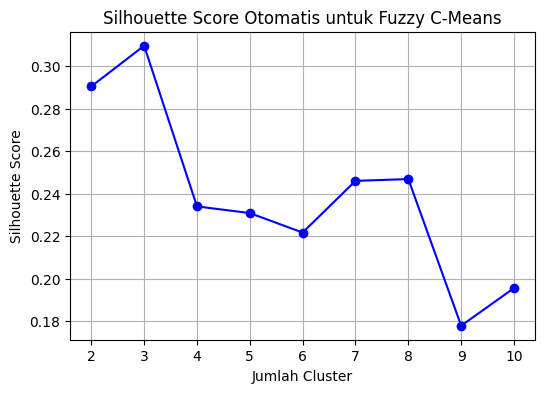

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import RobustScaler
import skfuzzy as fuzz

# Misalnya data_scaled adalah data yang telah distandarisasi
# data_scaled = RobustScaler().fit_transform(data)

range_k = range(2, 11)
hasil_silhouette_fcm = []

for k in range_k:
    # Transpose data karena skfuzzy cmeans butuh format (fitur, sampel)
    cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(
        scaled_data.T, c=k, m=2.0, error=0.005, maxiter=1000, init=None, seed=42
    )

    # Ambil label tertinggi dari keanggotaan
    labels = np.argmax(u, axis=0)

    # Hitung silhouette score
    score = silhouette_score(scaled_data, labels)
    hasil_silhouette_fcm.append((k, score))
    print(f"Jumlah Cluster: {k}, Silhouette Score: {score:.4f}")

# Simpan hasil ke DataFrame dan visualisasikan
df_silhouette_fcm = pd.DataFrame(hasil_silhouette_fcm, columns=["Jumlah Cluster", "Silhouette Score"])

# Plot
plt.figure(figsize=(6, 4))
plt.plot(df_silhouette_fcm["Jumlah Cluster"], df_silhouette_fcm["Silhouette Score"], marker='o', color='blue')
plt.title("Silhouette Score Otomatis untuk Fuzzy C-Means")
plt.xlabel("Jumlah Cluster")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.show()


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import davies_bouldin_score
import skfuzzy as fuzz

dbi_scores_fcm = []
cluster_range = range(2, 11)

for k in cluster_range:
    # Transpose data karena skfuzzy butuh format (fitur, sampel)
    cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(
        scaled_data.T, c=k, m=2.0, error=0.005, maxiter=1000, init=None, seed=42
    )

    # Konversi membership matrix menjadi hard label
    labels = np.argmax(u, axis=0)

    # Hitung DBI
    dbi = davies_bouldin_score(scaled_data, labels)
    dbi_scores_fcm.append(dbi)
    print(f"Fuzzy C-Means: Cluster {k}, DBI = {dbi:.4f}")

Fuzzy C-Means: Cluster 2, DBI = 1.1982
Fuzzy C-Means: Cluster 3, DBI = 1.0983
Fuzzy C-Means: Cluster 4, DBI = 1.0974
Fuzzy C-Means: Cluster 5, DBI = 1.1998
Fuzzy C-Means: Cluster 6, DBI = 1.2163
Fuzzy C-Means: Cluster 7, DBI = 1.0619
Fuzzy C-Means: Cluster 8, DBI = 1.0036
Fuzzy C-Means: Cluster 9, DBI = 1.1575
Fuzzy C-Means: Cluster 10, DBI = 1.0618
